# Cell 1 — Heart Disease Risk Prediction using Machine Learning

**Educational prototype only. This is NOT a medical diagnosis tool.**

This notebook predicts whether a patient record shows presence of heart disease, using the UCI Heart Disease (Cleveland) dataset. We compare five ML models, tune the best one, test it on unseen data, and save it.


Student: `<Sonmati singh>` | Roll No: `<24I5073>` | College: `<Iet davv indore>`

## Cell 2 — Install libraries
 Colab already has most libraries. We only install `ucimlrepo`, which downloads the dataset directly from the UCI repository.


In [18]:
!pip install -q ucimlrepo

## Cell 3 — Imports and settings
 Import all libraries, fix the random seed (so results are repeatable) and create folders for figures, models and results.


In [19]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

for folder in ["figures", "models", "results"]:
    os.makedirs(folder, exist_ok=True)
print("Setup complete.")

Setup complete.


## Cell 4 — Load the dataset
 `fetch_ucirepo(id=45)` downloads the UCI Heart Disease dataset (Cleveland data, 303 patients, 13 features). Features go into `X`, the original target (`num`, values 0-4) into `y_raw`.


Source: https://archive.ics.uci.edu/dataset/45/heart+disease (licence: CC BY 4.0)

In [20]:
heart = fetch_ucirepo(id=45)
X = heart.data.features.copy()
y_raw = heart.data.targets.copy()

print("Features shape:", X.shape)
print("Target shape  :", y_raw.shape)
print("Feature names :", list(X.columns))

Features shape: (303, 13)
Target shape  : (303, 1)
Feature names : ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


## Cell 5 — Dataset preview and exploration
 Look at the first rows, data types, summary statistics and the original target values.


In [21]:
display(X.head())
print()
X.info()
print()
display(X.describe().T)
print("\nOriginal target (num) counts:")
print(y_raw["num"].value_counts().sort_index())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
dtypes: float64(3), int64(10)
memory usage: 30.9 KB



,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2



Original target (num) counts:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


## Cell 6 — Data quality checks
 Check missing values, duplicate rows and class balance. Duplicates are checked on features + target together.


In [22]:
print("Missing values per column:")
print(X.isnull().sum()[X.isnull().sum() > 0] if X.isnull().sum().sum() > 0 else "None")

full_df = pd.concat([X, y_raw], axis=1)
print("\nDuplicate rows:", full_df.duplicated().sum())

# Convert the 0-4 target into a binary target: 0 = no disease, 1 = disease present
y = (y_raw["num"] > 0).astype(int)
y.name = "target"
print("\nBinary class counts (0 = no disease, 1 = disease):")
print(y.value_counts().sort_index())
print("\nBinary class percentage:")
print((y.value_counts(normalize=True).sort_index() * 100).round(1))

Missing values per column:
ca      4
thal    2
dtype: int64

Duplicate rows: 0

Binary class counts (0 = no disease, 1 = disease):
target
0    164
1    139
Name: count, dtype: int64

Binary class percentage:
target
0    54.1
1    45.9
Name: proportion, dtype: float64


## Cell 7 — Exploratory Data Analysis (graphs)
 Plots to understand the data: class balance, distributions, boxplots by class, categorical features by class and a correlation heatmap. Every figure is saved in `figures/`.


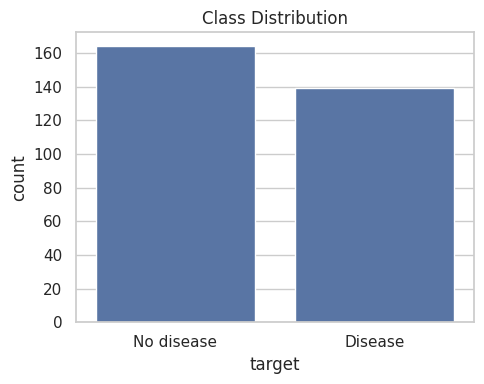

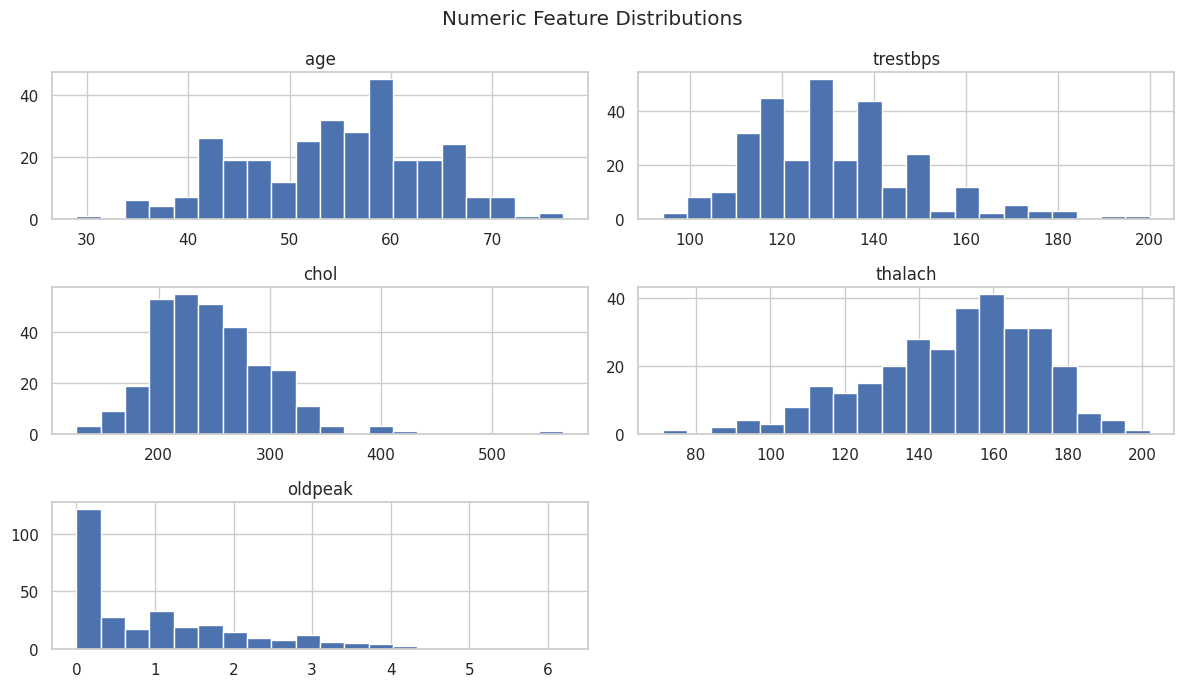

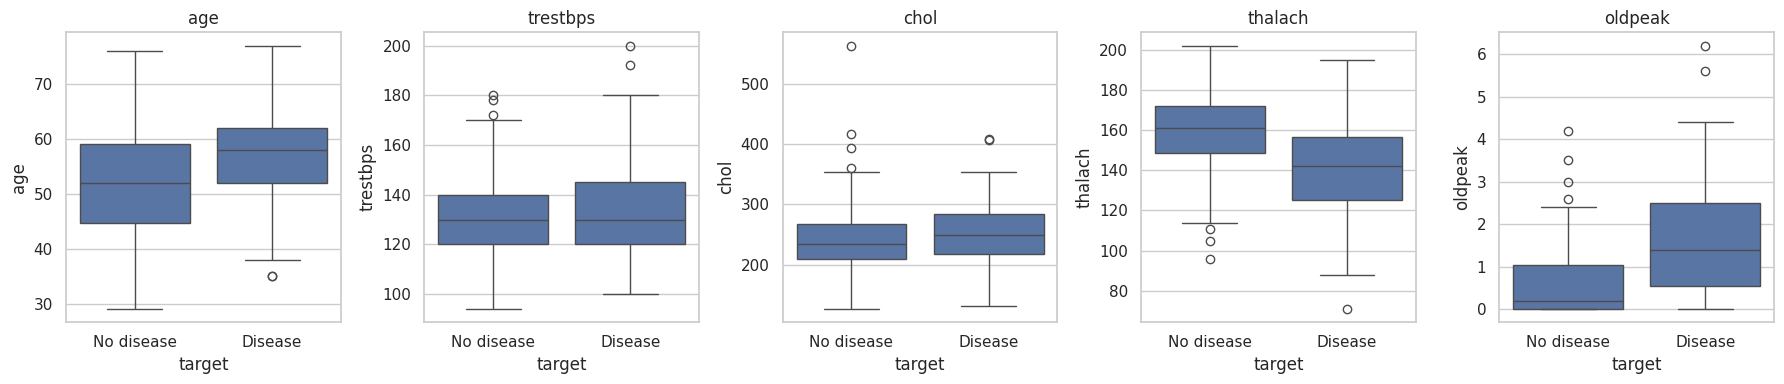

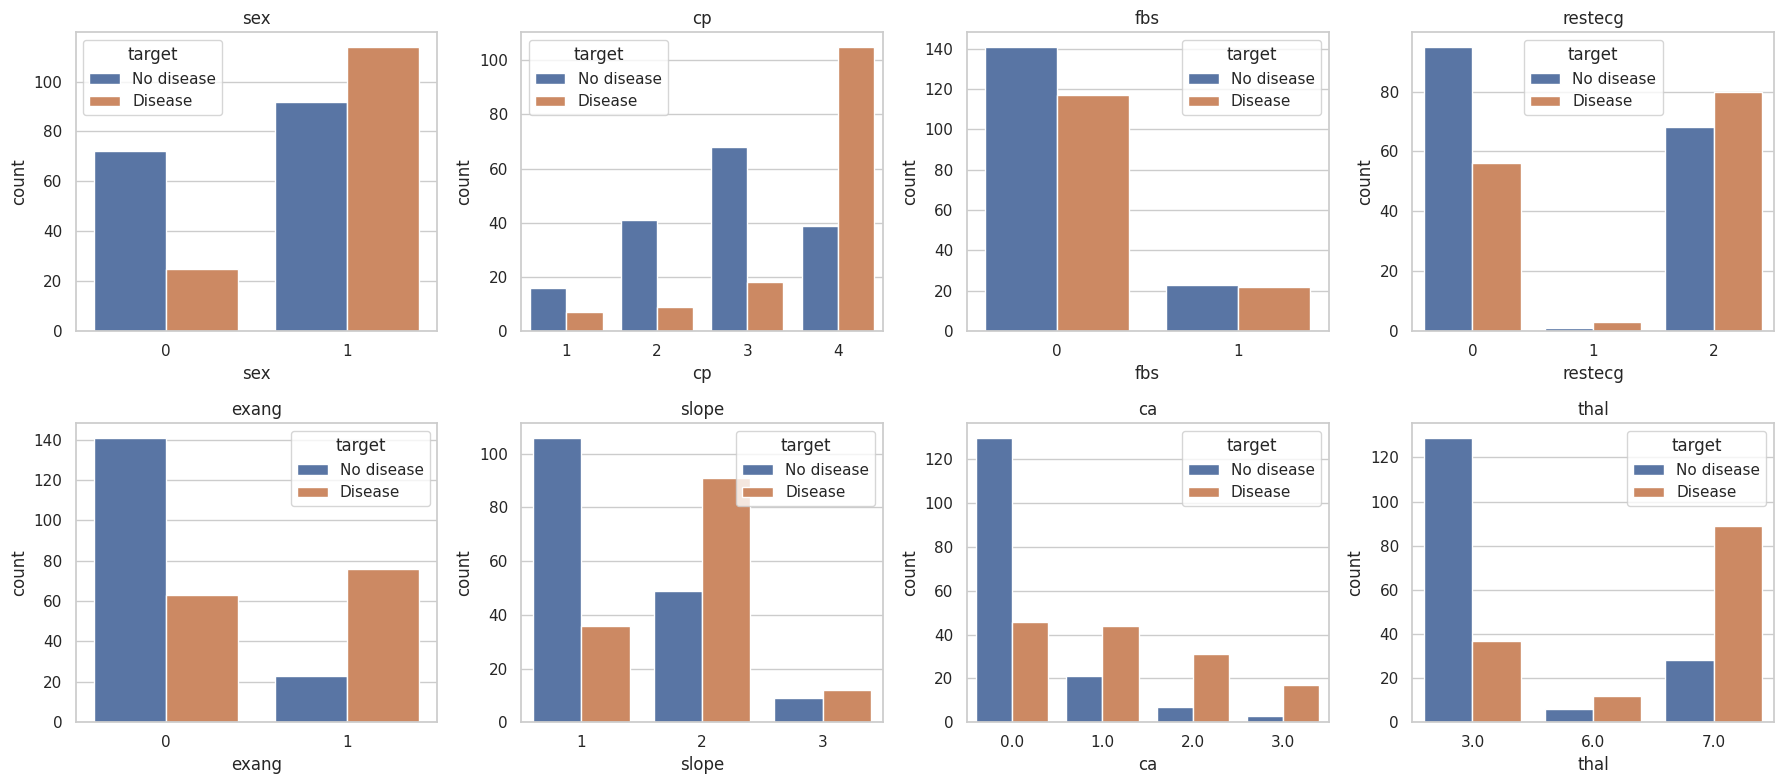

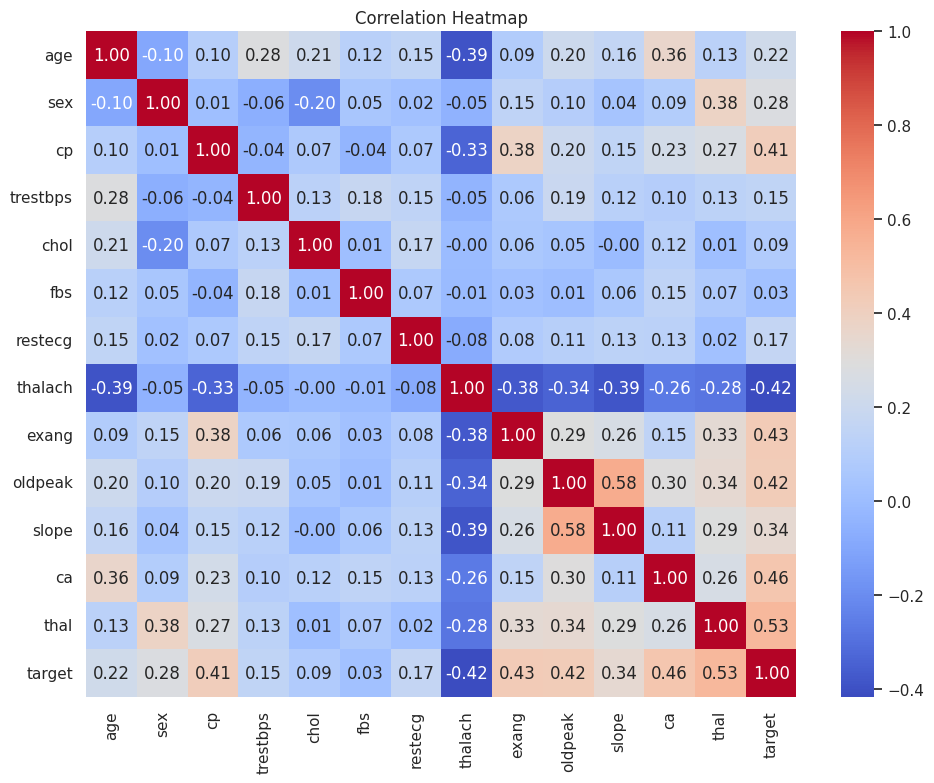

In [23]:
numeric_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

eda_df = X.copy()
eda_df["target"] = y

# 1. Class distribution
plt.figure(figsize=(5, 4))
sns.countplot(x="target", data=eda_df)
plt.xticks([0, 1], ["No disease", "Disease"])
plt.title("Class Distribution")
plt.tight_layout()
plt.savefig("figures/01_class_distribution.png", dpi=150)
plt.show()

# 2. Histograms of numeric features
X[numeric_cols].hist(bins=20, figsize=(12, 7))
plt.suptitle("Numeric Feature Distributions")
plt.tight_layout()
plt.savefig("figures/02_numeric_histograms.png", dpi=150)
plt.show()

# 3. Boxplots of numeric features by class
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(18, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(x="target", y=col, data=eda_df, ax=ax)
    ax.set_xticklabels(["No disease", "Disease"])
    ax.set_title(col)
plt.tight_layout()
plt.savefig("figures/03_boxplots_by_class.png", dpi=150)
plt.show()

# 4. Categorical features by class
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), categorical_cols):
    sns.countplot(x=col, hue="target", data=eda_df, ax=ax)
    ax.set_title(col)
    ax.legend(title="target", labels=["No disease", "Disease"])
plt.tight_layout()
plt.savefig("figures/04_categorical_by_class.png", dpi=150)
plt.show()

# 5. Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(eda_df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("figures/05_correlation_heatmap.png", dpi=150)
plt.show()

## Cell 8 — Train / test split
 We keep 20% of the data as a **test set** that is never used for training or tuning. The split is stratified so both sets keep the same class ratio. Validation is done later using 5-fold cross-validation on the training set only (the dataset is small, so cross-validation is more reliable than one fixed validation set).


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Train size:", X_train.shape, "| Test size:", X_test.shape)
print("Train class %:", (y_train.value_counts(normalize=True).sort_index() * 100).round(1).to_dict())
print("Test  class %:", (y_test.value_counts(normalize=True).sort_index() * 100).round(1).to_dict())

Train size: (242, 13) | Test size: (61, 13)
Train class %: {0: 54.1, 1: 45.9}
Test  class %: {0: 54.1, 1: 45.9}


## Cell 9 — Preprocessing pipeline
 Missing values are filled (median for numeric, most frequent for categorical), numeric features are scaled, and categorical features are one-hot encoded. All of this is inside a `Pipeline`, so it is learned only from training data in every fold. This prevents data leakage.


In [25]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
    ("cat", categorical_pipe, categorical_cols),
])
print("Preprocessor ready.")

Preprocessor ready.


## Cell 10 — Compare models using cross-validation
 Five models are compared with stratified 5-fold cross-validation on the training set. We use ROC-AUC as the main selection metric, and also record accuracy, precision, recall and F1.


In [26]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "SVM (RBF)": SVC(probability=True, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision",
           "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    row = {"model": name}
    for m in scoring:
        row[m] = res[f"test_{m}"].mean()
    row["roc_auc_std"] = res["test_roc_auc"].std()
    rows.append(row)

cv_results = pd.DataFrame(rows).sort_values("roc_auc", ascending=False).reset_index(drop=True)
display(cv_results.round(3))
cv_results.to_csv("results/cv_results.csv", index=False)

,model,accuracy,precision,recall,f1,roc_auc,roc_auc_std
0,Logistic Regression,0.847,0.877,0.783,0.825,0.902,0.014
1,Random Forest,0.818,0.817,0.783,0.795,0.897,0.029
2,SVM (RBF),0.814,0.830,0.765,0.789,0.888,0.024
3,KNN,0.822,0.823,0.783,0.799,0.871,0.039
4,Gradient Boosting,0.798,0.772,0.792,0.781,0.857,0.018


## Cell 11 — Plot model comparison


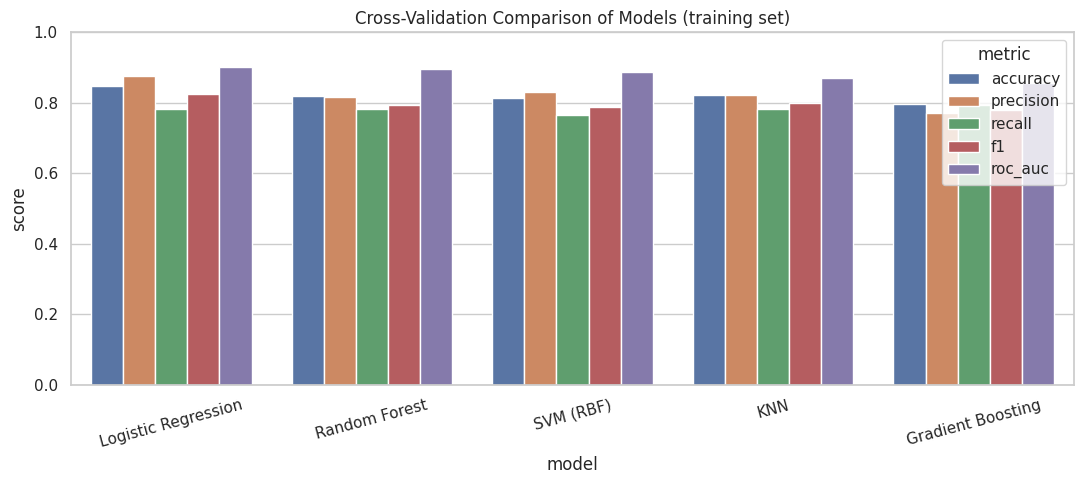

In [27]:
plot_df = cv_results.melt(id_vars="model",
                          value_vars=["accuracy", "precision", "recall", "f1", "roc_auc"],
                          var_name="metric", value_name="score")
plt.figure(figsize=(11, 5))
sns.barplot(x="model", y="score", hue="metric", data=plot_df)
plt.ylim(0, 1)
plt.title("Cross-Validation Comparison of Models (training set)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("figures/06_model_comparison.png", dpi=150)
plt.show()

## Cell 12 — Tune the best model
 The model with the highest cross-validated ROC-AUC is tuned with `GridSearchCV` (small grid, so it runs quickly on free Colab). Tuning uses only the training set.


In [28]:
param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10]},
    "KNN": {"model__n_neighbors": [3, 5, 7, 9, 11]},
    "SVM (RBF)": {"model__C": [0.1, 1, 10], "model__gamma": ["scale", 0.01, 0.1]},
    "Random Forest": {"model__n_estimators": [100, 300],
                      "model__max_depth": [None, 4, 8],
                      "model__min_samples_leaf": [1, 3]},
    "Gradient Boosting": {"model__n_estimators": [100, 200],
                          "model__learning_rate": [0.05, 0.1],
                          "model__max_depth": [2, 3]},
}

best_name = cv_results.loc[0, "model"]
print("Best model from cross-validation:", best_name)

best_pipe = Pipeline([("prep", preprocessor), ("model", models[best_name])])
grid = GridSearchCV(best_pipe, param_grids[best_name], cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)

final_model = grid.best_estimator_
print("Best parameters :", grid.best_params_)
print("Best CV ROC-AUC :", round(grid.best_score_, 4))

Best model from cross-validation: Logistic Regression
Best parameters : {'model__C': 1}
Best CV ROC-AUC : 0.9025


## Cell 13 — Predictions on unseen test data
 Now the tuned model predicts on the test set, which it has never seen. These are the final reported results.


In [29]:
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

pred_df = X_test.copy()
pred_df["actual"] = y_test.values
pred_df["predicted"] = y_pred
pred_df["probability_disease"] = y_prob.round(3)
display(pred_df.head(10))
pred_df.to_csv("results/test_predictions.csv", index=False)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,actual,predicted,probability_disease
219,59,1,4,138,271,0,2,182,0,0.0,1,0.0,3.0,0,0,0.209
271,66,1,4,160,228,0,2,138,0,2.3,1,0.0,6.0,0,1,0.601
89,51,0,3,130,256,0,2,149,0,0.5,1,0.0,3.0,0,0,0.021
101,34,1,1,118,182,0,2,174,0,0.0,1,0.0,3.0,0,0,0.033
67,54,1,3,150,232,0,2,165,0,1.6,1,0.0,7.0,0,0,0.312
244,60,0,3,120,178,1,0,96,0,0.0,1,0.0,3.0,0,0,0.016
185,63,0,2,140,195,0,0,179,0,0.0,1,2.0,3.0,0,0,0.117
233,74,0,2,120,269,0,2,121,1,0.2,1,1.0,3.0,0,0,0.349
168,35,1,4,126,282,0,2,156,1,0.0,1,0.0,7.0,1,1,0.722
197,45,0,4,138,236,0,2,152,1,0.2,2,0.0,3.0,0,0,0.347


## Cell 14 — Evaluation metrics
 For a medical screening task, **recall** (how many sick patients are caught) matters a lot, along with precision, F1 and ROC-AUC.


In [30]:
metrics = {
    "best_model": best_name,
    "best_params": {k: (v if isinstance(v, (int, float, str, type(None))) else str(v))
                    for k, v in grid.best_params_.items()},
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "precision": float(precision_score(y_test, y_pred)),
    "recall": float(recall_score(y_test, y_pred)),
    "f1": float(f1_score(y_test, y_pred)),
    "roc_auc": float(roc_auc_score(y_test, y_prob)),
    "test_samples": int(len(y_test)),
}
for k, v in metrics.items():
    print(f"{k:12s}: {round(v, 4) if isinstance(v, float) else v}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["No disease", "Disease"]))

with open("results/test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

best_model  : Logistic Regression
best_params : {'model__C': 1}
accuracy    : 0.8852
precision   : 0.8387
recall      : 0.9286
f1          : 0.8814
roc_auc     : 0.9665
test_samples: 61

Classification report:
              precision    recall  f1-score   support

  No disease       0.93      0.85      0.89        33
     Disease       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



## Cell 15 — Confusion matrix, ROC curve and feature importance
 The confusion matrix shows correct and wrong predictions. The ROC curve shows the trade-off between sensitivity and false alarms. Permutation importance shows which original features affect the prediction most (measured on the test set).


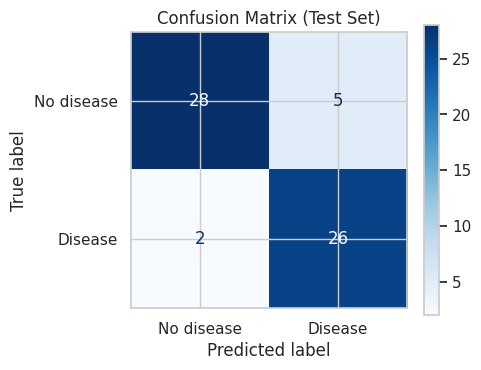

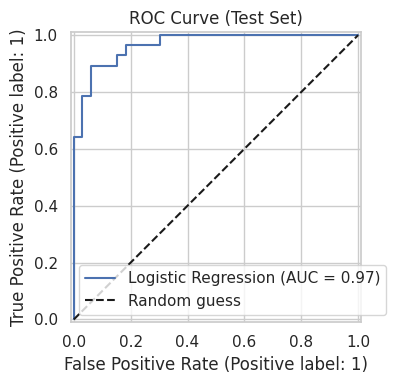

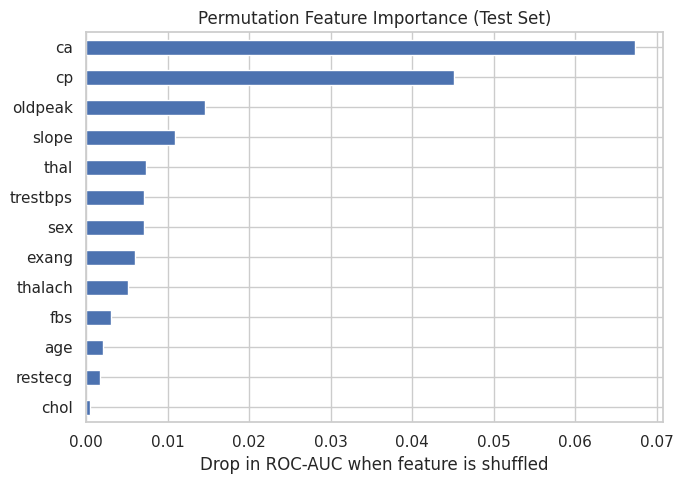

In [31]:
# Confusion matrix
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["No disease", "Disease"], cmap="Blues", ax=ax)
ax.set_title("Confusion Matrix (Test Set)")
plt.tight_layout()
plt.savefig("figures/07_confusion_matrix.png", dpi=150)
plt.show()

# ROC curve
fig, ax = plt.subplots(figsize=(5, 4))
RocCurveDisplay.from_predictions(y_test, y_prob, name=best_name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.legend()
ax.set_title("ROC Curve (Test Set)")
plt.tight_layout()
plt.savefig("figures/08_roc_curve.png", dpi=150)
plt.show()

# Permutation importance on original features
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=20, random_state=RANDOM_STATE)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
plt.figure(figsize=(7, 5))
imp.plot(kind="barh")
plt.xlabel("Drop in ROC-AUC when feature is shuffled")
plt.title("Permutation Feature Importance (Test Set)")
plt.tight_layout()
plt.savefig("figures/09_feature_importance.png", dpi=150)
plt.show()

## Cell 16 — Test with a new sample
 We create one new record manually and ask the model to predict. **This sample is an invented example for demonstration, not a real patient.** Edit the values to try other inputs.

Feature codes (UCI): sex 1=male 0=female; cp 1-4 chest pain type; fbs 1 if fasting sugar > 120 mg/dl; restecg 0-2; exang 1=exercise angina; slope 1-3; ca 0-3 vessels; thal 3 normal / 6 fixed defect / 7 reversible defect.

In [32]:
new_patient = pd.DataFrame([{
    "age": 58, "sex": 1, "cp": 4, "trestbps": 130, "chol": 250, "fbs": 0,
    "restecg": 0, "thalach": 120, "exang": 1, "oldpeak": 2.0,
    "slope": 2, "ca": 1, "thal": 7,
}])[X.columns]   # keep the same column order as the training data

prob = final_model.predict_proba(new_patient)[0, 1]
label = "Heart disease likely present" if prob >= 0.5 else "Heart disease likely absent"
print(f"Predicted probability of heart disease: {prob:.2%}")
print("Model output:", label)
print("\nDISCLAIMER: Educational prototype. Not a medical diagnosis.")

Predicted probability of heart disease: 98.72%
Model output: Heart disease likely present

DISCLAIMER: Educational prototype. Not a medical diagnosis.


## Cell 17 — Save and reload the model
 The whole pipeline (preprocessing + model) is saved with `joblib`, reloaded, and checked to give identical predictions.


In [33]:
model_path = "models/heart_disease_model.joblib"
joblib.dump(final_model, model_path)
print("Saved:", model_path, f"({os.path.getsize(model_path) / 1024:.1f} KB)")

loaded_model = joblib.load(model_path)
same = np.array_equal(loaded_model.predict(X_test), final_model.predict(X_test))
print("Reloaded model gives identical predictions:", same)

# Optional: download files to your computer/phone
# from google.colab import files
# files.download(model_path)

Saved: models/heart_disease_model.joblib (4.8 KB)
Reloaded model gives identical predictions: True


## Cell 18 — Final results and limitations
 The cell below prints the actual numbers from YOUR run. Copy only these into the report.


In [34]:
print("=" * 55)
print("FINAL RESULTS (from this run, unseen test set)")
print("=" * 55)
print(f"Best model : {best_name}")
print(f"Accuracy   : {metrics['accuracy']:.3f}")
print(f"Precision  : {metrics['precision']:.3f}")
print(f"Recall     : {metrics['recall']:.3f}")
print(f"F1-score   : {metrics['f1']:.3f}")
print(f"ROC-AUC    : {metrics['roc_auc']:.3f}")
print(f"Test samples: {metrics['test_samples']}")
print("=" * 55)

FINAL RESULTS (from this run, unseen test set)
Best model : Logistic Regression
Accuracy   : 0.885
Precision  : 0.839
Recall     : 0.929
F1-score   : 0.881
ROC-AUC    : 0.966
Test samples: 61


### Limitations
- Only 303 patients (Cleveland data), so the test set is small (about 61 records) and the scores can change noticeably with a different random split.
- Data comes from one hospital and an older period; the model may not generalise to other populations.
- The target was simplified from 0-4 to disease present/absent.
- No external validation dataset was used.
- This is an educational prototype and **not a substitute for professional medical diagnosis**.

